<a href="https://colab.research.google.com/github/ihsann2410010447/projek-statistika-Akbar-Ihsan-Nugraha/blob/main/Milestone4_Uji_Satu_Sampel_2410010447_Akbar_Ihsan_Nugraha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Milestone 4 — Uji Hipotesis Satu Sampel (Mean, Proporsi, Median)

**Mata Kuliah:** Statistika & Probabilitas (TIF1501) · CPMK072 (Sub-CPMK 072.2) · Milestone 4
**Nama / NIM:** _isi di sini_
**Dataset:** _nama dataset Milestone 1–3 Anda_

> **Cara pakai:** (1) isi sel **Konfigurasi** — nilai acuan (μ₀, p₀, median₀), **sumbernya**, arah uji beserta alasannya, dan ambang penting praktis; (2) jalankan semua sel; (3) tulis kesimpulan Anda di sel markdown bertanda `_..._`.
> Secara default notebook memakai **data demo sintetis** agar bisa langsung dijalankan — ganti `DATA_PATH` untuk memakai dataset Anda.

### Prinsip yang diuji di Milestone ini
1. **Nilai acuan harus punya sumber** (literatur, laporan resmi, standar, target bisnis) — bukan angka yang dipilih setelah melihat data.
2. **Arah uji ditetapkan SEBELUM uji dijalankan**, berdasarkan pertanyaan bisnis, lalu dijustifikasi.
3. **Asumsi dicek**; bila dilanggar, pakai uji alternatif.
4. **Signifikan secara statistik ≠ penting secara praktis** — laporkan p-value, CI, effect size, dan penilaian praktis.

# 🔧 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import TTestPower

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)
ALPHA = 0.05

# ⚙️ 2. Konfigurasi: Data, Nilai Acuan, Arah Uji

Isi bagian ini **sebelum** melihat hasil uji. Untuk tiap uji tuliskan:

| Parameter | Arti |
|---|---|
| `μ₀ / p₀ / M₀` | nilai acuan yang diuji |
| `SUMBER_*` | kutipan sumber nilai acuan (wajib — masuk checklist) |
| `ARAH_*` | `"two-sided"` (berbeda dari), `"greater"` (lebih dari), atau `"less"` (kurang dari) |
| `ALASAN_*` | mengapa arah itu dipilih (dari pertanyaan bisnis, bukan dari arah `x̄`) |
| `PRAKTIS_*` | selisih terkecil yang **berarti bagi bisnis** (satuan metrik; proporsi: 0.05 = 5 poin) |

Dataset tidak harus mirip NYC Taxi: cari klaim/target yang bermakna untuk dataset Anda — angka BPS, laporan industri, SLA, target KPI, atau klaim yang beredar.

In [ ]:
# ====== ISI BAGIAN INI ======
DATA_PATH = None   # contoh: "https://raw.githubusercontent.com/.../data.csv" atau "data.csv"

# --- UJI 1: MEAN ---
COL_MEAN      = "rating"
MU0           = 4.0
SUMBER_MU0    = "DEMO — ganti dengan sumber nyata (mis. target KPI perusahaan / laporan industri)"
ARAH_MEAN     = "greater"      # "two-sided" | "greater" | "less"
ALASAN_MEAN   = "Manajemen ingin tahu apakah rata-rata rating MELEBIHI target 4.0 (bukan sekadar berbeda)."
PRAKTIS_MEAN  = 0.10           # selisih rating < 0.10 dianggap tidak penting
SIGMA_MEAN    = None           # isi hanya jika σ populasi diketahui dari sumber tepercaya (→ z-test pembanding)

# --- UJI 2: PROPORSI ---
COL_PROP      = "metode"
KATEGORI      = "e-wallet"
P0            = 0.50
SUMBER_P0     = "DEMO — ganti dengan sumber nyata (mis. laporan Bank Indonesia / survei industri)"
ARAH_PROP     = "two-sided"
ALASAN_PROP   = "Klaim 'separuh transaksi pakai e-wallet' ingin dikonfirmasi dua arah: bisa lebih atau kurang."
PRAKTIS_PROP  = 0.05           # selisih < 5 poin persen dianggap tidak penting

# --- UJI 3: MEDIAN (untuk data skewed) ---
COL_MEDIAN    = "biaya"
MEDIAN0       = 25.0
SUMBER_M0     = "DEMO — ganti dengan sumber nyata (mis. standar harga / SLA)"
ARAH_MEDIAN   = "two-sided"
ALASAN_MEDIAN = "Median biaya standar 25; kita cek apakah menyimpang ke arah mana pun."
PRAKTIS_MEDIAN = 2.0           # selisih median < 2 dianggap tidak penting
# ============================

if DATA_PATH:
    df_my = pd.read_csv(DATA_PATH)
else:
    print("⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).")
    n_demo = 400
    df_my = pd.DataFrame({
        "rating": np.clip(rng.normal(4.12, 0.6, n_demo), 1, 5).round(2),
        "metode": rng.choice(["e-wallet", "tunai", "kartu"], n_demo, p=[0.53, 0.30, 0.17]),
        "biaya": rng.lognormal(3.2, 0.8, n_demo).round(2),     # skewed ke kanan
    })

print(f"Shape: {df_my.shape[0]:,} baris × {df_my.shape[1]} kolom")
df_my.head()

⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).
Shape: 400 baris × 3 kolom


,rating,metode,biaya
0,4.30,e-wallet,25.42
1,3.50,tunai,20.86
2,4.57,e-wallet,10.32
3,4.68,kartu,21.74
4,2.95,tunai,13.51


## 2.1 Kartu Hipotesis (ringkasan yang ditetapkan sebelum uji)

In [ ]:
kartu = pd.DataFrame([
    ["Mean",     f"{COL_MEAN}",                f"μ₀ = {MU0}",       ARAH_MEAN,   ALASAN_MEAN,   SUMBER_MU0],
    ["Proporsi", f"{COL_PROP} = '{KATEGORI}'", f"p₀ = {P0}",        ARAH_PROP,   ALASAN_PROP,   SUMBER_P0],
    ["Median",   f"{COL_MEDIAN}",              f"M₀ = {MEDIAN0}",   ARAH_MEDIAN, ALASAN_MEDIAN, SUMBER_M0],
], columns=["Uji", "Variabel", "Nilai acuan", "Arah", "Alasan arah", "Sumber acuan"])
pd.set_option("display.max_colwidth", 80)
kartu

,Uji,Variabel,Nilai acuan,Arah,Alasan arah,Sumber acuan
0,Mean,rating,μ₀ = 4.0,greater,Manajemen ingin tahu apakah rata-rata rating MELEBIHI target 4.0 (bukan seka...,DEMO — ganti dengan sumber nyata (mis. target KPI perusahaan / laporan indus...
1,Proporsi,metode = 'e-wallet',p₀ = 0.5,two-sided,Klaim 'separuh transaksi pakai e-wallet' ingin dikonfirmasi dua arah: bisa l...,DEMO — ganti dengan sumber nyata (mis. laporan Bank Indonesia / survei indus...
2,Median,biaya,M₀ = 25.0,two-sided,Median biaya standar 25; kita cek apakah menyimpang ke arah mana pun.,DEMO — ganti dengan sumber nyata (mis. standar harga / SLA)


# 🧰 3. Fungsi Bantu

In [ ]:
ALT_SM = {"two-sided": "two-sided", "greater": "larger", "less": "smaller"}   # nama arah di statsmodels
RESULTS = []                                                                   # untuk tabel ringkasan


def hipotesis(simbol, nilai, alt):
    """Susun H0 & H1 dari arah uji."""
    if alt == "two-sided": return f"{simbol} = {nilai}", f"{simbol} ≠ {nilai}"
    if alt == "greater":   return f"{simbol} ≤ {nilai}", f"{simbol} > {nilai}"
    return f"{simbol} ≥ {nilai}", f"{simbol} < {nilai}"


def laporan(judul, H0, H1, stat_name, stat, p, ci=None, effect=None, alpha=ALPHA):
    print("=" * 62); print(judul); print("=" * 62)
    print(f"  H₀ : {H0}"); print(f"  H₁ : {H1}")
    print(f"  {stat_name:<4}= {stat:.4f}"); print(f"  p  = {p:.4g}")
    if ci is not None:     print(f"  CI = [{ci[0]:.4f}, {ci[1]:.4f}]")
    if effect is not None: print(f"  Effect size: {effect}")
    keputusan = "TOLAK H₀" if p < alpha else "GAGAL TOLAK H₀"
    print(f"  Keputusan (α = {alpha}): {keputusan}\n")
    return keputusan


def praktis_label(p, selisih, praktis):
    """Signifikan secara statistik ≠ penting secara praktis."""
    sig = p < ALPHA
    if praktis is None:
        return "Signifikan (ambang praktis belum diisi)" if sig else "Tidak signifikan (ambang praktis belum diisi)"
    big = abs(selisih) >= praktis
    if sig and big:       return "Signifikan & PENTING secara praktis"
    if sig and not big:   return "Signifikan, tetapi selisih KECIL (di bawah ambang praktis)"
    if not sig and big:   return "Tidak signifikan, namun selisih ≥ ambang → kemungkinan UNDERPOWERED"
    return "Tidak signifikan & selisih kecil → tidak ada bukti perbedaan yang berarti"


def _catat(nama, uji, H0, alt, p, keputusan, selisih, praktis):
    RESULTS.append([nama, uji, H0, alt, p, keputusan, selisih, praktis_label(p, selisih, praktis)])


# ---------- UJI 1: MEAN ----------
def uji_mean(x, mu0, alt="two-sided", praktis=None, sigma=None, nama="Uji mean"):
    x = pd.Series(x).dropna().astype(float); n = len(x)
    # -- cek asumsi
    w, p_sw = stats.shapiro(x.sample(min(n, 500), random_state=0))
    sk = stats.skew(x)
    print(f"Cek asumsi: n = {n:,}, skewness = {sk:.2f}, Shapiro p = {p_sw:.4g} → {'normal' if p_sw > ALPHA else 'TIDAK normal'}")
    if n >= 30:
        print("  → n ≥ 30: CLT membuat t-test untuk MEAN tetap cukup aman.")
    elif p_sw < ALPHA or abs(sk) > 1:
        print("  ⚠️ n kecil DAN data tidak normal / sangat miring (Shapiro lemah pada n kecil, cek juga skewness & QQ-plot)")
        print("     → t-test untuk mean tidak dapat dipercaya. Pakai uji median (sign test) pada bagian 7.")
    # -- t-test (σ tidak diketahui → default)
    t, p = stats.ttest_1samp(x, mu0, alternative=alt)
    se, tcrit = stats.sem(x), stats.t.ppf(1 - (ALPHA / 2 if alt == "two-sided" else ALPHA), n - 1)
    if alt == "two-sided": ci = (x.mean() - tcrit * se, x.mean() + tcrit * se)
    elif alt == "greater": ci = (x.mean() - tcrit * se, np.inf)
    else:                  ci = (-np.inf, x.mean() + tcrit * se)
    selisih = x.mean() - mu0
    H0, H1 = hipotesis("μ", mu0, alt)
    kep = laporan(f"T-TEST SATU SAMPEL — {nama}", H0, H1, "t", t, p, ci, f"Cohen's d = {selisih / x.std(ddof=1):.3f}")
    print(f"  x̄ = {x.mean():.4f}, s = {x.std(ddof=1):.4f}, selisih (x̄ − μ₀) = {selisih:+.4f}")
    # -- z-test (hanya jika σ diketahui dari sumber tepercaya)
    if sigma:
        z = (x.mean() - mu0) / (sigma / np.sqrt(n))
        pz = {"two-sided": 2 * stats.norm.sf(abs(z)), "greater": stats.norm.sf(z), "less": stats.norm.cdf(z)}[alt]
        print(f"  [z-test, σ = {sigma} diketahui] z = {z:.3f}, p = {pz:.4g}  (bandingkan dengan t-test: s = {x.std(ddof=1):.3f})")
    # -- power terhadap ambang praktis
    if praktis:
        d_p = (-1 if alt == "less" else 1) * praktis / x.std(ddof=1); pw = TTestPower()   # uji kiri butuh effect size negatif
        n_req = pw.solve_power(effect_size=d_p, alpha=ALPHA, power=0.8, alternative=ALT_SM[alt])
        ach = pw.solve_power(effect_size=d_p, nobs=n, alpha=ALPHA, alternative=ALT_SM[alt])
        print(f"  Power: untuk mendeteksi selisih ≥ {praktis:g} (|d| = {abs(d_p):.3f}) butuh n ≈ {np.ceil(n_req):,.0f}; tersedia {n:,} → power ≈ {ach:.0%}")
    print(f"  ➜ {praktis_label(p, selisih, praktis)}\n")
    _catat(nama, "t-test 1 sampel", H0, alt, p, kep, selisih, praktis)
    return p


# ---------- UJI 2: PROPORSI ----------
def uji_prop(k, n, p0, alt="two-sided", praktis=None, nama="Uji proporsi"):
    phat = k / n
    ok = n * p0 >= 10 and n * (1 - p0) >= 10
    print(f"Syarat z-test: n·p₀ = {n*p0:,.0f}, n·(1−p₀) = {n*(1-p0):,.0f} → {'✅ terpenuhi (≥ 10)' if ok else '⚠️ TIDAK terpenuhi → pakai binomial exact'}")
    z, p_z = proportions_ztest(k, n, value=p0, prop_var=p0, alternative=ALT_SM[alt])   # SE memakai p₀
    p_ex = stats.binomtest(k, n, p0, alternative=alt).pvalue
    method, a = ("wilson", ALPHA if alt == "two-sided" else 2 * ALPHA) if ok else ("beta", ALPHA if alt == "two-sided" else 2 * ALPHA)
    lo, hi = proportion_confint(k, n, alpha=a, method=method)
    ci = (lo, hi) if alt == "two-sided" else ((lo, 1.0) if alt == "greater" else (0.0, hi))
    h = 2 * np.arcsin(np.sqrt(phat)) - 2 * np.arcsin(np.sqrt(p0))
    selisih = phat - p0
    p_use = p_z if ok else p_ex
    H0, H1 = hipotesis("p", p0, alt)
    kep = laporan(f"{'Z-TEST' if ok else 'BINOMIAL EXACT'} PROPORSI — {nama}", H0, H1, "z", z, p_use, ci,
                  f"selisih = {selisih*100:+.2f} poin persen, Cohen's h = {h:.3f}")
    print(f"  p̂ = {k:,}/{n:,} = {phat:.2%}   |   p z-test = {p_z:.4g}{'' if ok else ' (TIDAK valid: syarat n·p₀ gagal)'}, p binomial exact = {p_ex:.4g}   (CI: {'Wilson' if ok else 'Clopper-Pearson'})")
    print(f"  ➜ {praktis_label(p_use, selisih, praktis)}\n")
    _catat(nama, "z-test proporsi" if ok else "binomial exact", H0, alt, p_use, kep, selisih, praktis)
    return p_use


# ---------- UJI 3: MEDIAN ----------
def sign_test_alt(x, m0, alt="two-sided"):
    """Sign test dengan pilihan arah. M = (pos − neg)/2 (definisi sama dgn statsmodels.sign_test)."""
    x = np.asarray(x, float); pos, neg = int((x > m0).sum()), int((x < m0).sum()); m = pos + neg
    M = (pos - neg) / 2
    p = stats.binomtest(min(pos, neg), m, 0.5).pvalue if alt == "two-sided" else stats.binomtest(pos, m, 0.5, alternative=alt).pvalue
    return M, p, pos, neg


def uji_median(x, m0, alt="two-sided", praktis=None, nama="Uji median", boot=2000):
    x = pd.Series(x).dropna().astype(float).values; n = len(x)
    M, p, pos, neg = sign_test_alt(x, m0, alt)
    med = np.median(x)
    bm = np.array([np.median(x[rng.integers(0, n, n)]) for _ in range(boot)])
    ci = tuple(np.percentile(bm, [2.5, 97.5]))
    H0, H1 = hipotesis("median", m0, alt)
    kep = laporan(f"SIGN TEST — {nama}", H0, H1, "M", M, p, ci, f"{pos/(pos+neg):.1%} data di atas {m0:g} (H₀: 50%)")
    print(f"  Median sampel = {med:.4f}, selisih (median − M₀) = {med - m0:+.4f}")
    print(f"  Di bawah {m0:g} = {neg:,}, di atas = {pos:,}, tepat sama = {n - pos - neg} (dibuang)   |   CI median = bootstrap persentil 95%")
    sk = stats.skew(x)
    try:
        pw = stats.wilcoxon(x - m0, alternative=alt).pvalue
        print(f"  [Pembanding] Wilcoxon p = {pw:.4g}  — valid hanya jika distribusi SIMETRIS (skewness data = {sk:.2f}"
              f"{' → asumsi simetri DILANGGAR, andalkan sign test' if abs(sk) > 1 else ''})")
    except ValueError:
        pass
    print(f"  ➜ {praktis_label(p, med - m0, praktis)}\n")
    _catat(nama, "sign test", H0, alt, p, kep, med - m0, praktis)
    return p


def ringkasan():
    t = pd.DataFrame(RESULTS, columns=["Klaim", "Uji", "H₀", "Arah", "p-value", "Keputusan", "Selisih", "Penilaian praktis"])
    t["Selisih"] = t["Selisih"].map(lambda v: f"{v:+.4g}")
    t["p-value"] = t["p-value"].map(lambda v: f"{v:.2e}" if v < 0.001 else f"{v:.4f}")
    return t

# 🔍 4. EDA Singkat — Bentuk Distribusi

Lihat dulu bentuk data; ini menentukan uji mana yang cocok. Garis merah = nilai acuan.

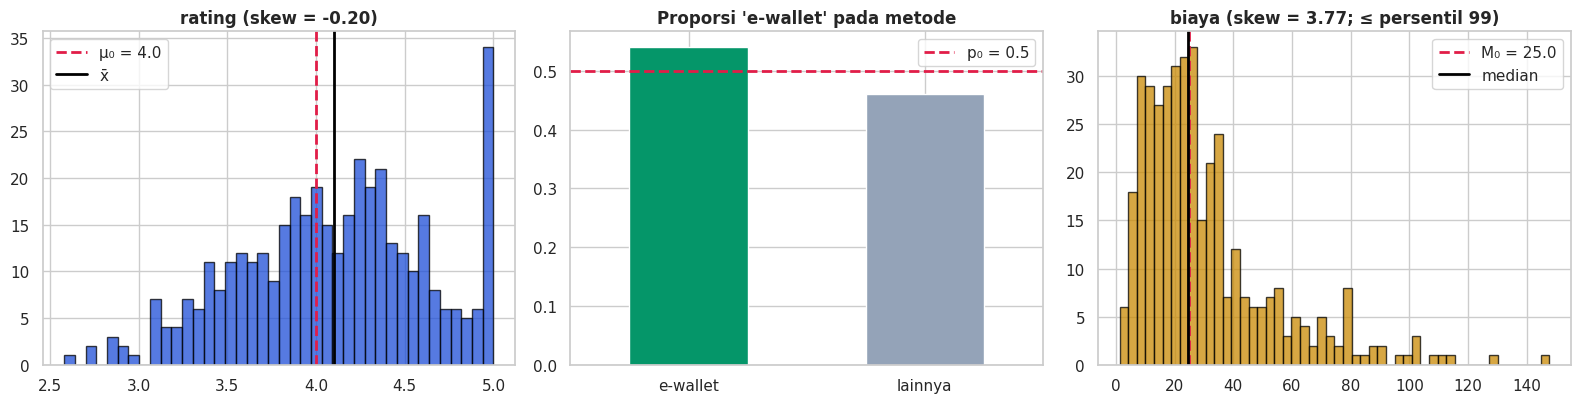

Skewness rating      : -0.20  → cukup simetris
Skewness biaya       : +3.77  → sangat miring (|skew| > 1): mean mudah ditarik outlier; untuk klaim MEDIAN gunakan sign test


In [ ]:
x_mean = df_my[COL_MEAN].dropna().astype(float)
x_med  = df_my[COL_MEDIAN].dropna().astype(float)
prop_s = df_my[COL_PROP].dropna()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(x_mean, bins=40, color="#1D4ED8", edgecolor="black", alpha=0.75)
axes[0].axvline(MU0, color="#E11D48", ls="--", lw=2, label=f"μ₀ = {MU0}"); axes[0].axvline(x_mean.mean(), color="black", lw=2, label="x̄")
axes[0].set_title(f"{COL_MEAN} (skew = {stats.skew(x_mean):.2f})", fontweight="bold"); axes[0].legend()

pd.Series({KATEGORI: (prop_s == KATEGORI).mean(), "lainnya": (prop_s != KATEGORI).mean()}).plot(kind="bar", ax=axes[1], color=["#059669", "#94A3B8"], rot=0)
axes[1].axhline(P0, color="#E11D48", ls="--", lw=2, label=f"p₀ = {P0}")
axes[1].set_title(f"Proporsi '{KATEGORI}' pada {COL_PROP}", fontweight="bold"); axes[1].legend()

axes[2].hist(x_med[x_med <= x_med.quantile(0.99)], bins=50, color="#CA8A04", edgecolor="black", alpha=0.75)
axes[2].axvline(MEDIAN0, color="#E11D48", ls="--", lw=2, label=f"M₀ = {MEDIAN0}"); axes[2].axvline(x_med.median(), color="black", lw=2, label="median")
axes[2].set_title(f"{COL_MEDIAN} (skew = {stats.skew(x_med):.2f}; ≤ persentil 99)", fontweight="bold"); axes[2].legend()
plt.tight_layout(); plt.show()
for nm, v in [(COL_MEAN, x_mean), (COL_MEDIAN, x_med)]:
    sk = stats.skew(v)
    print(f"Skewness {nm:<12}: {sk:+.2f}  → {'sangat miring (|skew| > 1): mean mudah ditarik outlier; untuk klaim MEDIAN gunakan sign test' if abs(sk) > 1 else 'cukup simetris'}")

# 🧮 5. Uji 1 — Mean (t-test satu sampel)

Pilih kolom numerik yang punya nilai acuan bermakna. Fungsi akan: cek asumsi (Shapiro, skewness, n) → t-test sesuai arah → CI → Cohen's d → power terhadap ambang praktis → penilaian signifikan vs penting.

In [ ]:
print(f"Sumber μ₀ : {SUMBER_MU0}")
print(f"Arah uji  : {ARAH_MEAN}  ← {ALASAN_MEAN}\n")
p_mean = uji_mean(df_my[COL_MEAN], MU0, ARAH_MEAN, PRAKTIS_MEAN, SIGMA_MEAN, nama=f"rata-rata {COL_MEAN}")

Sumber μ₀ : DEMO — ganti dengan sumber nyata (mis. target KPI perusahaan / laporan industri)
Arah uji  : greater  ← Manajemen ingin tahu apakah rata-rata rating MELEBIHI target 4.0 (bukan sekadar berbeda).

Cek asumsi: n = 400, skewness = -0.20, Shapiro p = 4.935e-05 → TIDAK normal
  → n ≥ 30: CLT membuat t-test untuk MEAN tetap cukup aman.
T-TEST SATU SAMPEL — rata-rata rating
  H₀ : μ ≤ 4.0
  H₁ : μ > 4.0
  t   = 3.7113
  p  = 0.0001177
  CI = [4.0552, inf]
  Effect size: Cohen's d = 0.186
  Keputusan (α = 0.05): TOLAK H₀

  x̄ = 4.0994, s = 0.5357, selisih (x̄ − μ₀) = +0.0994
  Power: untuk mendeteksi selisih ≥ 0.1 (|d| = 0.187) butuh n ≈ 179; tersedia 400 → power ≈ 98%
  ➜ Signifikan, tetapi selisih KECIL (di bawah ambang praktis)



**Kesimpulan (tulis sendiri):**
- _Statistik:_ t = ..., p = ..., CI = [..., ...], d = ... → tolak / gagal tolak H₀.
- _Praktis:_ _selisih x̄ − μ₀ = ... (satuan). Apakah selisih ini penting bagi keputusan bisnis? CI menyingkirkan / tidak menyingkirkan nilai ...?_
- _Ingat:_ "gagal tolak" ≠ klaim terbukti benar._

# 📊 6. Uji 2 — Proporsi (z-test / binomial exact)

Fungsi mengecek syarat n·p₀ ≥ 10 dan n·(1−p₀) ≥ 10. Jika terpenuhi memakai z-test (SE dengan p₀) + CI Wilson; jika tidak, otomatis memakai binomial exact + CI Clopper-Pearson.

In [ ]:
print(f"Sumber p₀ : {SUMBER_P0}")
print(f"Arah uji  : {ARAH_PROP}  ← {ALASAN_PROP}\n")
k = int((df_my[COL_PROP] == KATEGORI).sum())
n = int(df_my[COL_PROP].notna().sum())
p_prop = uji_prop(k, n, P0, ARAH_PROP, PRAKTIS_PROP, nama=f"proporsi {COL_PROP} = '{KATEGORI}'")

Sumber p₀ : DEMO — ganti dengan sumber nyata (mis. laporan Bank Indonesia / survei industri)
Arah uji  : two-sided  ← Klaim 'separuh transaksi pakai e-wallet' ingin dikonfirmasi dua arah: bisa lebih atau kurang.

Syarat z-test: n·p₀ = 200, n·(1−p₀) = 200 → ✅ terpenuhi (≥ 10)
Z-TEST PROPORSI — proporsi metode = 'e-wallet'
  H₀ : p = 0.5
  H₁ : p ≠ 0.5
  z   = 1.6000
  p  = 0.1096
  CI = [0.4910, 0.5882]
  Effect size: selisih = +4.00 poin persen, Cohen's h = 0.080
  Keputusan (α = 0.05): GAGAL TOLAK H₀

  p̂ = 216/400 = 54.00%   |   p z-test = 0.1096, p binomial exact = 0.121   (CI: Wilson)
  ➜ Tidak signifikan & selisih kecil → tidak ada bukti perbedaan yang berarti



**Kesimpulan (tulis sendiri):**
- _Statistik:_ p̂ = ..., z = ..., p = ..., CI = [..., ...].
- _Praktis:_ _selisih ... poin persen — apakah mengubah keputusan bisnis? Informasi apa yang masih dibutuhkan (biaya, skala pengguna, dsb.)?_

# 🔬 7. Uji 3 — Median (sign test untuk data skewed)

Sign test menghitung berapa data di atas vs di bawah M₀ lalu menguji binomial p = 0.5 — **tanpa asumsi bentuk distribusi**. Wilcoxon ditampilkan hanya sebagai pembanding: ia mengasumsikan distribusi simetris, sehingga tidak boleh diandalkan pada data yang sangat skewed.

CI median dihitung dengan **bootstrap** (median tidak punya rumus SE sederhana).

In [ ]:
print(f"Sumber M₀ : {SUMBER_M0}")
print(f"Arah uji  : {ARAH_MEDIAN}  ← {ALASAN_MEDIAN}\n")
p_med = uji_median(df_my[COL_MEDIAN], MEDIAN0, ARAH_MEDIAN, PRAKTIS_MEDIAN, nama=f"median {COL_MEDIAN}")

Sumber M₀ : DEMO — ganti dengan sumber nyata (mis. standar harga / SLA)
Arah uji  : two-sided  ← Median biaya standar 25; kita cek apakah menyimpang ke arah mana pun.

SIGN TEST — median biaya
  H₀ : median = 25.0
  H₁ : median ≠ 25.0
  M   = -4.0000
  p  = 0.7264
  CI = [22.6749, 26.0000]
  Effect size: 49.0% data di atas 25 (H₀: 50%)
  Keputusan (α = 0.05): GAGAL TOLAK H₀

  Median sampel = 24.6300, selisih (median − M₀) = -0.3700
  Di bawah 25 = 204, di atas = 196, tepat sama = 0 (dibuang)   |   CI median = bootstrap persentil 95%
  [Pembanding] Wilcoxon p = 0.05176  — valid hanya jika distribusi SIMETRIS (skewness data = 3.77 → asumsi simetri DILANGGAR, andalkan sign test)
  ➜ Tidak signifikan & selisih kecil → tidak ada bukti perbedaan yang berarti



**Kesimpulan (tulis sendiri):**
- _Statistik:_ M = ..., p = ..., CI bootstrap median = [..., ...].
- _Praktis:_ _..._
- _Mengapa sign test (bukan t-test/Wilcoxon) untuk kolom ini?_ _(sebut skewness & outlier)_

# 📊 8. Ringkasan Semua Uji

In [ ]:
ringkasan()

,Klaim,Uji,H₀,Arah,p-value,Keputusan,Selisih,Penilaian praktis
0,rata-rata rating,t-test 1 sampel,μ ≤ 4.0,greater,1.18e-04,TOLAK H₀,+0.0994,"Signifikan, tetapi selisih KECIL (di bawah ambang praktis)"
1,proporsi metode = 'e-wallet',z-test proporsi,p = 0.5,two-sided,0.1096,GAGAL TOLAK H₀,+0.04,Tidak signifikan & selisih kecil → tidak ada bukti perbedaan yang berarti
2,median biaya,sign test,median = 25.0,two-sided,0.7264,GAGAL TOLAK H₀,-0.37,Tidak signifikan & selisih kecil → tidak ada bukti perbedaan yang berarti


# 🧭 9. Kesimpulan Akhir & Catatan Keterbatasan

Tulis ringkasan temuan dalam bahasa bisnis (2–4 kalimat per uji), lalu keterbatasannya.

**Temuan utama:**
1. _Mean:_ _..._
2. _Proporsi:_ _..._
3. _Median:_ _..._

**Keterbatasan / risiko:**
- _Apakah nilai acuan relevan dengan populasi dataset saya (konteks, periode, wilayah)?_
- _Apakah sampel mewakili populasi (cara pengambilan data)?_
- _Apakah ada uji yang underpowered? Apakah saya menguji beberapa klaim sekaligus (risiko false positive bertambah)?_
- _Apakah asumsi tiap uji terpenuhi? Uji alternatif apa yang saya pakai bila tidak?_

# ✅ 10. Checklist Submit Milestone 4

- [ ] Minimal 3 uji satu sampel (mean, proporsi, median)
- [ ] Sumber setiap nilai acuan (μ₀ / p₀ / median₀) dituliskan — **bukan** teks "DEMO"
- [ ] Arah uji ditetapkan & dijustifikasi sebelum uji dijalankan
- [ ] Cek asumsi + uji alternatif bila asumsi dilanggar
- [ ] p-value + CI + effect size + kesimpulan praktis
- [ ] `DATA_PATH`, nama kolom, nilai acuan, dan ambang praktis sudah diganti ke dataset Anda (bukan data demo)
- [ ] README diperbarui, commit: `"Milestone 4: one-sample hypothesis tests"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 13**